In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 0. Load Locally Downloaded Dataset File
# ---------------------------------------------------------
# Update file_path to match your downloaded file (e.g., "wine.data", "wine.csv", or a full path)
file_path = Path("wine.data")

columns = [
    "Class",
    "Alcohol",
    "Malic_acid",
    "Ash",
    "Alcalinity_of_ash",
    "Magnesium",
    "Total_phenols",
    "Flavanoids",
    "Nonflavanoid_phenols",
    "Proanthocyanins",
    "Color_intensity",
    "Hue",
    "OD280_OD315_of_diluted_wines",
    "Proline",
]

# UCI's `wine.data` has no header row; if you saved a CSV with headers, set `header=0` and `names=None`
df = pd.read_csv(file_path, header=None, names=columns)

# ---------------------------------------------------------
# Common Requirements: Structural Inspection
# ---------------------------------------------------------
print("=== HEAD (First 5 rows) ===")
print(df.head())

print("\n=== TAIL (Last 5 rows) ===")
print(df.tail())

print("\n=== SHAPE (Rows, Columns) ===")
print(df.shape)

print("\n=== INFO ===")
print(df.info())

print("\n=== DESCRIBE ===")
print(df.describe())


# ---------------------------------------------------------
# Q1: How Many Wines Belong to Each Class?
# ---------------------------------------------------------
print("\n=== Q1: WINE COUNT PER CLASS ===")
class_counts = df["Class"].value_counts().sort_index()
print(class_counts)





=== HEAD (First 5 rows) ===
   Class  Alcohol  Malic_acid   Ash  Alcalinity_of_ash  Magnesium  \
0      1    14.23        1.71  2.43               15.6        127   
1      1    13.20        1.78  2.14               11.2        100   
2      1    13.16        2.36  2.67               18.6        101   
3      1    14.37        1.95  2.50               16.8        113   
4      1    13.24        2.59  2.87               21.0        118   

   Total_phenols  Flavanoids  Nonflavanoid_phenols  Proanthocyanins  \
0           2.80        3.06                  0.28             2.29   
1           2.65        2.76                  0.26             1.28   
2           2.80        3.24                  0.30             2.81   
3           3.85        3.49                  0.24             2.18   
4           2.80        2.69                  0.39             1.82   

   Color_intensity   Hue  OD280_OD315_of_diluted_wines  Proline  
0             5.64  1.04                          3.92     1065 

In [ ]:
# ---------------------------------------------------------
# Q2: Mean, Median, Minimum, and Maximum Alcohol Values (NumPy)
# ---------------------------------------------------------
alcohol_arr = df["Alcohol"].to_numpy()

mean_alcohol = np.mean(alcohol_arr)
median_alcohol = np.median(alcohol_arr)
min_alcohol = np.min(alcohol_arr)
max_alcohol = np.max(alcohol_arr)

print("\n=== Q2: ALCOHOL STATISTICS (NUMPY) ===")
print(f"Mean Alcohol:    {mean_alcohol:.4f}")
print(f"Median Alcohol:  {median_alcohol:.4f}")
print(f"Minimum Alcohol: {min_alcohol:.4f}")
print(f"Maximum Alcohol: {max_alcohol:.4f}")


=== Q2: ALCOHOL STATISTICS (NUMPY) ===
Mean Alcohol:    13.0006
Median Alcohol:  13.0500
Minimum Alcohol: 11.0300
Maximum Alcohol: 14.8300


In [ ]:
# ---------------------------------------------------------
# Q3: Which Class Has the Highest Average Alcohol & Magnesium?
# ---------------------------------------------------------
class_alc_mag = df.groupby("Class")[["Alcohol", "Magnesium"]].mean()
top_alcohol_class = class_alc_mag["Alcohol"].idxmax()
top_magnesium_class = class_alc_mag["Magnesium"].idxmax()

print("\n=== Q3: AVERAGE ALCOHOL & MAGNESIUM BY CLASS ===")
print(class_alc_mag)
print(
    f"Highest Average Alcohol Class:   Class {top_alcohol_class} "
    f"({class_alc_mag.loc[top_alcohol_class, 'Alcohol']:.4f})"
)
print(
    f"Highest Average Magnesium Class: Class {top_magnesium_class} "
    f"({class_alc_mag.loc[top_magnesium_class, 'Magnesium']:.4f})"
)


=== Q3: AVERAGE ALCOHOL & MAGNESIUM BY CLASS ===
         Alcohol   Magnesium
Class                       
1      13.744746  106.338983
2      12.278732   94.549296
3      13.153750   99.312500
Highest Average Alcohol Class:   Class 1 (13.7447)
Highest Average Magnesium Class: Class 1 (106.3390)


In [ ]:
# ---------------------------------------------------------
# Q4: Which Records Have the Highest Color Intensity?
# ---------------------------------------------------------
sorted_by_color = df.sort_values(by="Color_intensity", ascending=False)
high_color_threshold = sorted_by_color["Color_intensity"].iloc[4]  # top 5 cutoff
top_color_records = sorted_by_color[
    sorted_by_color["Color_intensity"] >= high_color_threshold
]

print("\n=== Q4: RECORDS WITH HIGHEST COLOR INTENSITY ===")
print(
    top_color_records[
        ["Class", "Color_intensity", "Alcohol", "Malic_acid", "Magnesium"]
    ]
)



=== Q4: RECORDS WITH HIGHEST COLOR INTENSITY ===
     Class  Color_intensity  Alcohol  Malic_acid  Magnesium
158      3            13.00    14.34        1.68         98
159      3            11.75    13.48        1.67         89
151      3            10.80    12.79        2.67        112
166      3            10.68    13.45        3.70        111
153      3            10.52    13.23        3.30         98


In [ ]:
# ---------------------------------------------------------
# Q5: Check for Missing Values and Duplicates
# ---------------------------------------------------------
print("\n=== Q5: MISSING VALUES PER COLUMN ===")
print(df.isnull().sum())
print("Total missing values:", int(df.isnull().sum().sum()))

print("\n=== Q5: DUPLICATE RECORDS ===")
num_duplicates = int(df.duplicated().sum())
print("Number of exact duplicate rows:", num_duplicates)



=== Q5: MISSING VALUES PER COLUMN ===
Class                           0
Alcohol                         0
Malic_acid                      0
Ash                             0
Alcalinity_of_ash               0
Magnesium                       0
Total_phenols                   0
Flavanoids                      0
Nonflavanoid_phenols            0
Proanthocyanins                 0
Color_intensity                 0
Hue                             0
OD280_OD315_of_diluted_wines    0
Proline                         0
dtype: int64
Total missing values: 0

=== Q5: DUPLICATE RECORDS ===
Number of exact duplicate rows: 0



=== Q6: AVERAGE ALCOHOL, MALIC ACID & COLOR INTENSITY BY CLASS ===
         Alcohol  Malic_acid  Color_intensity
Class                                        
1      13.744746    2.010678         5.528305
2      12.278732    1.932676         3.086620
3      13.153750    3.333750         7.396250


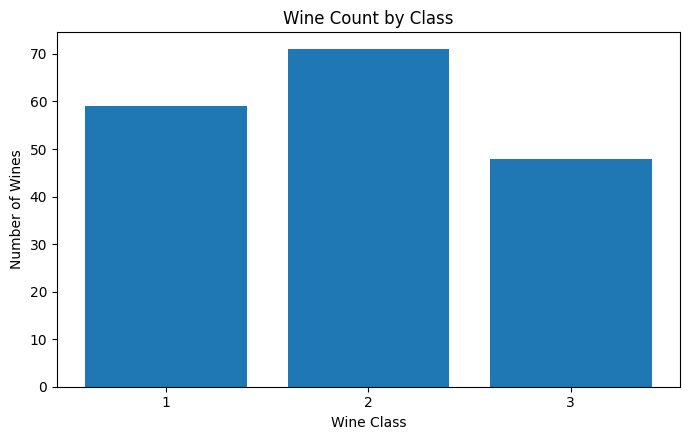

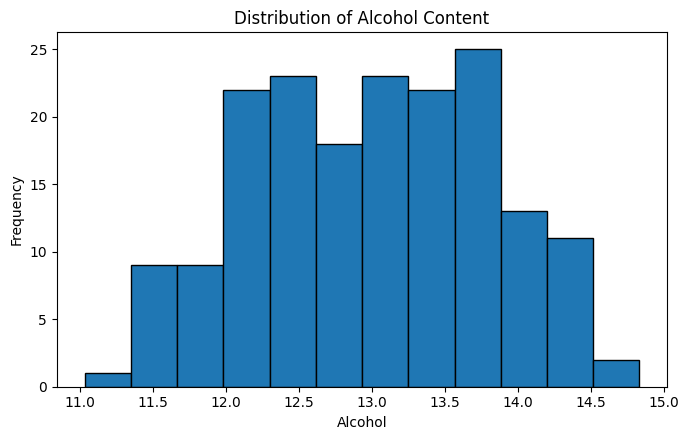

In [ ]:
# ---------------------------------------------------------
# Q6: Compare Average Alcohol, Malic Acid & Color Intensity by Class
# ---------------------------------------------------------
class_comparison = df.groupby("Class")[
    ["Alcohol", "Malic_acid", "Color_intensity"]
].mean()

print("\n=== Q6: AVERAGE ALCOHOL, MALIC ACID & COLOR INTENSITY BY CLASS ===")
print(class_comparison)

# ---------------------------------------------------------
# Visualizations: (1) Class-Count Bar Chart & (2) Alcohol Histogram
# ---------------------------------------------------------
# Chart 1: Class-Count Bar Chart
plt.figure(figsize=(7, 4.5))
plt.bar(class_counts.index.astype(str), class_counts.values)
plt.title("Wine Count by Class")
plt.xlabel("Wine Class")
plt.ylabel("Number of Wines")
plt.tight_layout()
plt.show()

# Chart 2: Alcohol Histogram
plt.figure(figsize=(7, 4.5))
plt.hist(alcohol_arr, bins=12, edgecolor="black")
plt.title("Distribution of Alcohol Content")
plt.xlabel("Alcohol")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()